# A/B test: does moving the first progress gate from level 30 to level 40 change retention?

**Business question.** Cookie Cats, a mobile puzzle game, makes players wait (or pay) at "gates" before they can
keep playing. The team tested moving the first gate from level 30 to level 40. Players were randomly assigned
on install to the existing experience (`gate_30`, control) or the new one (`gate_40`, treatment).

**Decision to make.** Ship `gate_40`, or keep `gate_30`?

**Analysis plan**

| | Metric | Why |
|---|---|---|
| Primary | Day-7 retention | Medium-term engagement is what the gate is meant to protect |
| Secondary | Day-1 retention | Early signal of any change in player behaviour |
| Guardrail | Game rounds in first 14 days | The change must not cut engagement |

Checks before trusting any result: sample ratio, statistical power, multiple comparisons, and no peeking.

**Result in one line.** Moving the gate to level 40 **reduced day-7 retention by 0.82 percentage points
(19.02% → 18.20%, 95% CI −1.33 to −0.31 pp, p = 0.0016)**, a 4.3% relative drop that survives correction for
multiple metrics. A small sample-ratio imbalance means the size of the drop needs confirming, but even in the
worst case the estimate stays negative and any gain above 0.01 pp is ruled out at 95% confidence.
Recommendation: **keep the gate at level 30.**

In [1]:
# Run from the repository root so the SQL files and data paths resolve the same way everywhere.
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from prodanalytics.data import load_cookie_cats
from prodanalytics.experiment import (bayesian_ab, bootstrap_diff, bootstrap_proportion_diff, holm_adjust,
                                      minimum_detectable_effect, required_sample_size, srm_test,
                                      two_proportion_test)
from prodanalytics.peeking import simulate_peeking
from prodanalytics import plotting as P

P.apply_style()
pd.set_option("display.float_format", "{:.4f}".format)

## 1. Data and sanity checks

In [2]:
players = load_cookie_cats()
print(players.shape)
print("missing values:", int(players.isna().sum().sum()), "| duplicate players:", int(players.userid.duplicated().sum()))
players.sum_gamerounds.describe(percentiles=[0.5, 0.9, 0.99, 0.999]).to_frame().T

(90189, 5)
missing values: 0 | duplicate players: 0


,count,mean,std,min,50%,90%,99%,99.9%,max
sum_gamerounds,90189.0000,51.8725,195.0509,0.0000,16.0000,134.0000,493.0000,1073.6240,49854.0000


In [3]:
players.nlargest(3, "sum_gamerounds")

,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False


One control player logged **49,854 rounds in 14 days**, roughly 20 times the next highest. That is almost
certainly a logging error or a bot. It cannot move the retention metrics (it is one player out of 90,189), but it
would distort a mean of game rounds, so the engagement guardrail is analysed with a median, a rank test and a
mean capped at the 99.9th percentile.

## 2. Metric definitions in SQL

In [4]:
headline = duckdb.sql(open("sql/experiment_metrics.sql").read()).df()
headline

,arm,players,retained_day1,retained_day7,day1_retention,day7_retention,median_rounds,capped_mean_rounds,max_rounds
0,gate_30,44700,20034,8502,0.4482,0.1902,17.0000,51.0300,49854
1,gate_40,45489,20119,8279,0.4423,0.1820,16.0000,50.9400,2640


## 3. Is the traffic split healthy? (sample ratio mismatch)

The experiment was designed as a 50/50 split. If the observed split is very unlikely under 50/50, something in
assignment or logging is broken and the comparison may be biased.

In [5]:
control = players[players.version == "gate_30"]
treatment = players[players.version == "gate_40"]
srm = srm_test(len(control), len(treatment))
print(f"control {srm.n_control:,} | treatment {srm.n_treatment:,} | treatment share {srm.observed_share_treatment:.2%}")
print(f"chi-square = {srm.chi2:.2f}, p = {srm.p_value:.4f}")

control 44,700 | treatment 45,489 | treatment share 50.44%
chi-square = 6.90, p = 0.0086


The treatment group is 789 players larger than control (50.44% vs 50%, p = 0.0086). That does not trip the
strict p < 0.001 alarm many large experimentation platforms use, but it would at 1%, so it cannot be ignored.
Rather than assume it away, section 5 tests how sensitive the result is to it.

## 4. Was the test big enough? (power)

With about 45,000 players per arm, this is the smallest change each metric could reliably detect
(80% power, 5% two-sided significance):

In [6]:
n = min(len(control), len(treatment))
for metric in ["retention_7", "retention_1"]:
    base = control[metric].mean()
    print(f"{metric}: baseline {base:.2%}, minimum detectable effect {minimum_detectable_effect(base, n):.2%} points")
print("players per arm needed to detect a 0.5 pp change in day-7 retention:",
      f"{required_sample_size(control.retention_7.mean(), 0.005):,}")

retention_7: baseline 19.02%, minimum detectable effect 0.74% points
retention_1: baseline 44.82%, minimum detectable effect 0.93% points
players per arm needed to detect a 0.5 pp change in day-7 retention: 97,679


The test has 80% power to detect a change of about 0.74 percentage points in day-7 retention. Smaller real
effects could be missed, so any non-significant result should be read through its confidence interval rather
than as proof of no effect.

## 5. Primary metric: day-7 retention

In [7]:
x_c, n_c = int(control.retention_7.sum()), len(control)
x_t, n_t = int(treatment.retention_7.sum()), len(treatment)
d7 = two_proportion_test(x_c, n_c, x_t, n_t)
_, boot_ci, boot_draws = bootstrap_proportion_diff(x_c, n_c, x_t, n_t, n_boot=100_000, seed=42)
bayes = bayesian_ab(x_c, n_c, x_t, n_t, seed=42)

pd.DataFrame({
    "value": [d7.rate_control, d7.rate_treatment, d7.abs_diff, d7.rel_lift, d7.p_value,
              bayes.prob_treatment_better, bayes.expected_loss_treatment],
}, index=["day-7 retention, gate_30", "day-7 retention, gate_40", "absolute difference", "relative change",
          "p-value (two-proportion z-test)", "P(gate_40 better) (Bayesian)", "expected loss if shipping gate_40"])

,value
"day-7 retention, gate_30",0.1902
"day-7 retention, gate_40",0.1820
absolute difference,-0.0082
relative change,-0.0431
p-value (two-proportion z-test),0.0016
P(gate_40 better) (Bayesian),0.0008
expected loss if shipping gate_40,0.0082


In [8]:
print(f"95% CI for the difference (Wald):      {d7.abs_ci[0]:+.4f} to {d7.abs_ci[1]:+.4f}")
print(f"95% CI for the difference (bootstrap): {boot_ci[0]:+.4f} to {boot_ci[1]:+.4f}")
print(f"95% CI for the relative change:        {d7.rel_ci[0]:+.2%} to {d7.rel_ci[1]:+.2%}")

95% CI for the difference (Wald):      -0.0133 to -0.0031
95% CI for the difference (bootstrap): -0.0133 to -0.0031
95% CI for the relative change:        -6.89% to -1.66%


The frequentist test, the bootstrap and the Bayesian model all describe the same picture. With a sample
this large they are expected to agree; their value is in how they frame the decision. The Bayesian view
gives the probability that `gate_40` is better (under 0.1%) and the retention we would expect to lose by
shipping it (about 0.8 points).

### Sensitivity to the sample-ratio imbalance

If the 789 extra treatment players are genuine random assignments, the estimate above stands. The worst case
for the conclusion is that they are extra **non-returning** players logged into treatment by mistake (for
example, duplicate install events). Removing them from the treatment group shows how much the result could move:

In [9]:
surplus = len(treatment) - len(control)
worst = two_proportion_test(x_c, n_c, x_t, n_t - surplus)
print(f"worst case: day-7 retention {worst.rate_control:.2%} -> {worst.rate_treatment:.2%}, "
      f"diff {worst.abs_diff * 100:+.2f} pp (95% CI {worst.abs_ci[0] * 100:+.2f} to {worst.abs_ci[1] * 100:+.2f} pp), "
      f"p = {worst.p_value:.3f}")

worst case: day-7 retention 19.02% -> 18.52%, diff -0.50 pp (95% CI -1.01 to +0.01 pp), p = 0.056


In that extreme case, the drop shrinks to 0.50 points and is no longer significant (p = 0.056). The estimate
still points against `gate_40`, and its confidence interval rules out any gain larger than 0.01 points. So the
evidence for a benefit is absent in every scenario; what depends on resolving the imbalance is how large the
loss is.

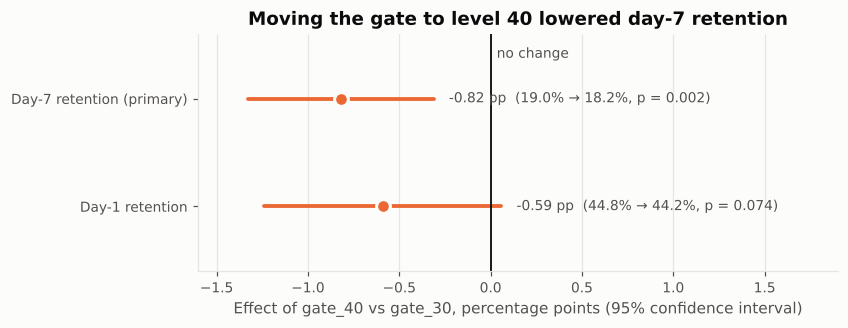

In [10]:
effects = [("Day-1 retention", two_proportion_test(int(control.retention_1.sum()), len(control),
                                                   int(treatment.retention_1.sum()), len(treatment))),
           ("Day-7 retention (primary)", d7)]
fig, ax = plt.subplots(figsize=(7.5, 2.8))
for y, (label, res) in enumerate(effects):
    lo, hi = res.abs_ci
    ax.plot([lo * 100, hi * 100], [y, y], color=P.TREATMENT, lw=2.5, solid_capstyle="round")
    ax.plot(res.abs_diff * 100, y, "o", color=P.TREATMENT, ms=9, mec=P.SURFACE, mew=2)
    ax.annotate(f"{res.abs_diff * 100:+.2f} pp  ({res.rate_control:.1%} → {res.rate_treatment:.1%}, p = {res.p_value:.3f})",
                (hi * 100, y), xytext=(10, 0), textcoords="offset points", va="center", fontsize=9, color=P.TEXT_2)
ax.axvline(0, color=P.TEXT, lw=1.2)
ax.annotate("no change", (0, 1.38), xytext=(4, 0), textcoords="offset points", fontsize=9, color=P.TEXT_2)
ax.set_yticks([0, 1], [e[0] for e in effects])
ax.set_ylim(-0.6, 1.6)
ax.set_xlim(-1.6, 1.9)
ax.set_xlabel("Effect of gate_40 vs gate_30, percentage points (95% confidence interval)")
ax.set_title("Moving the gate to level 40 lowered day-7 retention")
ax.grid(axis="y", visible=False)
P.save(fig, "ab_retention_effects")
plt.show()

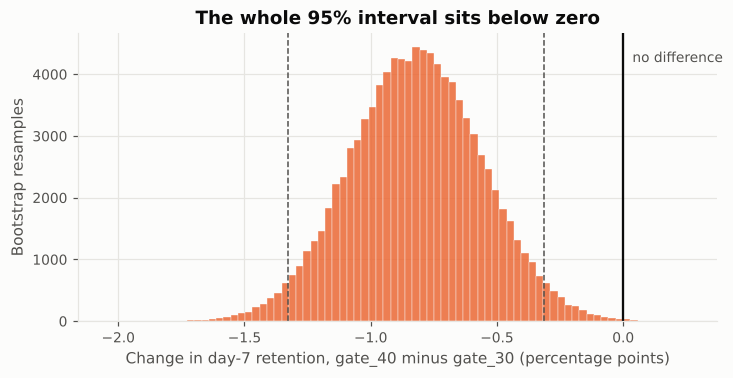

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist(boot_draws * 100, bins=80, color=P.TREATMENT, alpha=0.85, edgecolor=P.SURFACE, linewidth=0.3)
ax.axvline(0, color=P.TEXT, lw=1.5)
ax.annotate("no difference", (0, ax.get_ylim()[1] * 0.9), xytext=(6, 0), textcoords="offset points", fontsize=9,
            color=P.TEXT_2)
for v in boot_ci:
    ax.axvline(v * 100, color=P.TEXT_2, lw=1, ls="--")
ax.set_xlabel("Change in day-7 retention, gate_40 minus gate_30 (percentage points)")
ax.set_ylabel("Bootstrap resamples")
ax.set_title("The whole 95% interval sits below zero")
P.save(fig, "ab_bootstrap_day7")
plt.show()

## 6. Secondary metric and guardrail

In [12]:
d1 = two_proportion_test(int(control.retention_1.sum()), len(control),
                         int(treatment.retention_1.sum()), len(treatment))
print(f"Day-1 retention: {d1.rate_control:.2%} -> {d1.rate_treatment:.2%}, "
      f"diff {d1.abs_diff * 100:+.2f} pp (95% CI {d1.abs_ci[0] * 100:+.2f} to {d1.abs_ci[1] * 100:+.2f} pp), "
      f"p = {d1.p_value:.3f}")

cap = players.sum_gamerounds.quantile(0.999)
mw = stats.mannwhitneyu(treatment.sum_gamerounds, control.sum_gamerounds, alternative="two-sided")
eng_diff, eng_ci, _ = bootstrap_diff(control.sum_gamerounds.clip(upper=cap).to_numpy(),
                                     treatment.sum_gamerounds.clip(upper=cap).to_numpy(),
                                     n_boot=2_000, seed=42)
print(f"Game rounds: median {control.sum_gamerounds.median():.0f} -> {treatment.sum_gamerounds.median():.0f}; "
      f"capped mean diff {eng_diff:+.2f} rounds (95% CI {eng_ci[0]:+.2f} to {eng_ci[1]:+.2f}); "
      f"Mann-Whitney p = {mw.pvalue:.3f}")

Day-1 retention: 44.82% -> 44.23%, diff -0.59 pp (95% CI -1.24 to +0.06 pp), p = 0.074


Game rounds: median 17 -> 16; capped mean diff -0.10 rounds (95% CI -1.38 to +1.18); Mann-Whitney p = 0.050


Day-1 retention moves in the same direction but is not significant, before or after correction. One plausible
reason is that the gate only affects players who progress far enough to reach it, which many will not do on
their first day; the data does not record levels, so this cannot be checked directly.

The engagement guardrail is borderline rather than clearly safe. The median falls by one round and the rank
test sits right at p = 0.050 (0.10 after correction), while the capped mean difference is only −0.1 rounds
(95% CI −1.4 to +1.2). Any engagement effect is small, and it points the same way as retention, so it adds no
case for shipping `gate_40`.

## 7. Correcting for multiple metrics

Testing three metrics raises the chance of a false positive somewhere. Holm's correction controls that
family-wise error rate.

In [13]:
raw = [d7.p_value, d1.p_value, mw.pvalue]
pd.DataFrame({"raw p": raw, "Holm-adjusted p": holm_adjust(raw)},
             index=["day-7 retention (primary)", "day-1 retention", "game rounds (guardrail)"])

,raw p,Holm-adjusted p
day-7 retention (primary),0.0016,0.0047
day-1 retention,0.0744,0.1004
game rounds (guardrail),0.0502,0.1004


The day-7 result remains significant after correction (adjusted p ≈ 0.005).

## 8. Why the analysis waited for the full sample

A common mistake is to check results every day and stop as soon as p < 0.05. The simulation below runs 2,000
A/A tests, where both arms are identical so every "win" is false, and compares checking 20 times against
checking once at the planned sample size.

In [14]:
peek = simulate_peeking(p=0.19, n_per_group=20_000, looks=20, n_sims=2_000, seed=42)
peek

{'fixed_horizon_false_positive_rate': 0.0525,
 'peeking_false_positive_rate': 0.242,
 'looks': 20,
 'n_sims': 2000}

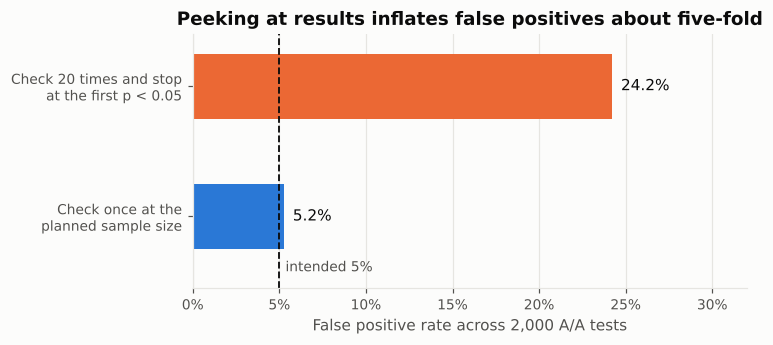

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 3.0))
labels = ["Check once at the\nplanned sample size", "Check 20 times and stop\nat the first p < 0.05"]
vals = [peek["fixed_horizon_false_positive_rate"], peek["peeking_false_positive_rate"]]
bars = ax.barh(labels, vals, color=[P.CONTROL, P.TREATMENT], height=0.5)
ax.axvline(0.05, color=P.TEXT, lw=1.2, ls="--")
ax.annotate("intended 5%", (0.05, -0.42), xytext=(4, 0), textcoords="offset points", fontsize=9, color=P.TEXT_2)
ax.set_ylim(-0.55, 1.4)
for b, v in zip(bars, vals):
    ax.annotate(f"{v:.1%}", (v, b.get_y() + b.get_height() / 2), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=10, color=P.TEXT)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlim(0, 0.32)
ax.set_xlabel("False positive rate across 2,000 A/A tests")
ax.set_title("Peeking at results inflates false positives about five-fold")
ax.grid(axis="y", visible=False)
P.save(fig, "ab_peeking_simulation")
plt.show()

## 9. Decision

**Keep the first gate at level 30.** Moving it to level 40 cost about 0.8 percentage points of day-7 retention
(a 4.3% relative drop). The result survives correction for multiple metrics, and engagement offers no
offsetting gain. Even under the worst-case reading of the sample-ratio imbalance, the estimate stays negative
and a meaningful gain is ruled out, so the decision not to ship `gate_40` is well supported. The size of the
loss is less certain: the point estimate is 0.5 to 0.8 points depending on the scenario, with confidence
intervals spanning roughly 0 to 1.3 points. Pinning it down depends on why the groups are unbalanced.

**Caveats**
* The split is slightly unbalanced (p = 0.0086). Before reporting the size of the effect, I would check the
  assignment and event logging to find out which scenario in section 5 applies.
* Retention is measured only to day 7; longer-term effects (and any revenue impact from the gate) are not observed.
* No pre-experiment data is available, so variance reduction such as CUPED was not possible.

**What I would add in a live product setting**
* CUPED or regression adjustment on pre-period activity, to cut variance and detect smaller effects.
* A sequential testing design (for example, alpha spending) if stakeholders need interim reads.
* Pre-registered segments (new vs returning users, platform, country) to check the effect is not driven by one group.
* A long-term holdout to confirm the effect persists beyond the novelty period.